# Temporal Sequence Construction + LSTM **Forecasting**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Import libraries

In [ ]:
import os
import json
import random
import warnings
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    LSTM,
    Dense,
    Dropout,
    BatchNormalization
)

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("Step 10 libraries loaded successfully.")

TensorFlow version: 2.20.0
Step 10 libraries loaded successfully.


Define project paths

In [ ]:
PROJECT_DIR = "/content/drive/MyDrive/GC210_Retail_Forecasting"

RAW_DIR = os.path.join(
    PROJECT_DIR,
    "data",
    "raw"
)

PROCESSED_DIR = os.path.join(
    PROJECT_DIR,
    "data",
    "processed"
)

SUPERVISED_DIR = os.path.join(
    PROCESSED_DIR,
    "supervised"
)

SEQUENCE_DIR = os.path.join(
    PROCESSED_DIR,
    "sequences"
)

MODEL_DIR = os.path.join(
    PROJECT_DIR,
    "models"
)

LSTM_MODEL_DIR = os.path.join(
    MODEL_DIR,
    "lstm"
)

RESULTS_DIR = os.path.join(
    PROJECT_DIR,
    "results"
)

METRICS_DIR = os.path.join(
    RESULTS_DIR,
    "metrics"
)

PREDICTIONS_DIR = os.path.join(
    RESULTS_DIR,
    "predictions"
)

FIGURES_DIR = os.path.join(
    RESULTS_DIR,
    "figures"
)

for folder in [
    SEQUENCE_DIR,
    LSTM_MODEL_DIR,
    METRICS_DIR,
    PREDICTIONS_DIR,
    FIGURES_DIR
]:
    os.makedirs(
        folder,
        exist_ok=True
    )

print("Step 10 directories ready.")

Step 10 directories ready.


Define required files

In [ ]:
TRAIN_PATH = os.path.join(
    SUPERVISED_DIR,
    "train_supervised_28d.parquet"
)

VAL_PATH = os.path.join(
    SUPERVISED_DIR,
    "validation_supervised_28d.parquet"
)

TEST_PATH = os.path.join(
    SUPERVISED_DIR,
    "test_supervised_28d.parquet"
)

CONFIG_PATH = os.path.join(
    SUPERVISED_DIR,
    "supervised_config.json"
)

SALES_PATH = os.path.join(
    RAW_DIR,
    "sales_train_evaluation.csv"
)

required_files = [
    TRAIN_PATH,
    VAL_PATH,
    TEST_PATH,
    CONFIG_PATH,
    SALES_PATH
]

all_exist = True

for path in required_files:

    if os.path.exists(path):
        print("FOUND   ->", path)

    else:
        print("MISSING ->", path)
        all_exist = False

if not all_exist:
    raise FileNotFoundError(
        "Required files are missing. "
        "Check Step 5 and raw M5 data."
    )

print("\nAll required Step 10 files found.")

FOUND   -> /content/drive/MyDrive/GC210_Retail_Forecasting/data/processed/supervised/train_supervised_28d.parquet
FOUND   -> /content/drive/MyDrive/GC210_Retail_Forecasting/data/processed/supervised/validation_supervised_28d.parquet
FOUND   -> /content/drive/MyDrive/GC210_Retail_Forecasting/data/processed/supervised/test_supervised_28d.parquet
FOUND   -> /content/drive/MyDrive/GC210_Retail_Forecasting/data/processed/supervised/supervised_config.json
FOUND   -> /content/drive/MyDrive/GC210_Retail_Forecasting/data/raw/sales_train_evaluation.csv

All required Step 10 files found.


Load supervised datasets

In [ ]:
train_df = pd.read_parquet(
    TRAIN_PATH
)

val_df = pd.read_parquet(
    VAL_PATH
)

test_df = pd.read_parquet(
    TEST_PATH
)

with open(
    CONFIG_PATH,
    "r"
) as f:

    config = json.load(f)

TARGETS = config["targets"]

HORIZON = len(TARGETS)

SEQUENCE_LENGTH = 28

print("=" * 70)
print("STEP 10 DATA")
print("=" * 70)

print("Training   :", train_df.shape)
print("Validation :", val_df.shape)
print("Test       :", test_df.shape)

print("\nSequence length :", SEQUENCE_LENGTH)
print("Forecast horizon:", HORIZON)

STEP 10 DATA
Training   : (79200, 71)
Validation : (300, 71)
Test       : (300, 71)

Sequence length : 28
Forecast horizon: 28


Check forecast-origin dates

In [ ]:
for dataset in [
    train_df,
    val_df,
    test_df
]:

    dataset["date"] = pd.to_datetime(
        dataset["date"]
    )

print(
    "Training origins:",
    train_df["date"].min(),
    "to",
    train_df["date"].max()
)

print(
    "Validation origin:",
    val_df["date"].min()
)

print(
    "Test origin:",
    test_df["date"].min()
)

print(
    "\nTrain series:",
    train_df["series_key"].nunique()
)

print(
    "Validation series:",
    val_df["series_key"].nunique()
)

print(
    "Test series:",
    test_df["series_key"].nunique()
)

Training origins: 2011-03-01 00:00:00 to 2016-03-15 00:00:00
Validation origin: 2016-03-27 00:00:00
Test origin: 2016-04-24 00:00:00

Train series: 300
Validation series: 300
Test series: 300


Load M5 evaluation sales history

In [ ]:
sales_wide = pd.read_csv(
    SALES_PATH
)

print(
    "Raw evaluation sales:",
    sales_wide.shape
)

display(
    sales_wide.head()
)

Raw evaluation sales: (30490, 1947)


,id,item_id,dept_id,cat_id,store_id,state_id,d_1,d_2,d_3,d_4,...,d_1932,d_1933,d_1934,d_1935,d_1936,d_1937,d_1938,d_1939,d_1940,d_1941
0,HOBBIES_1_001_CA_1_evaluation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,2,4,0,0,0,0,3,3,0,1
1,HOBBIES_1_002_CA_1_evaluation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,0,1,2,1,1,0,0,0,0,0
2,HOBBIES_1_003_CA_1_evaluation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,1,0,2,0,0,0,2,3,0,1
3,HOBBIES_1_004_CA_1_evaluation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,1,1,0,4,0,1,3,0,2,6
4,HOBBIES_1_005_CA_1_evaluation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,0,0,0,2,1,0,0,2,1,0


Normalize M5 series IDs

In [ ]:
def normalize_m5_id(x):

    return (
        str(x)
        .replace("_validation", "")
        .replace("_evaluation", "")
    )


sales_wide["series_key"] = (
    sales_wide["id"]
    .apply(normalize_m5_id)
)

required_series = set(
    pd.concat([
        train_df["series_key"],
        val_df["series_key"],
        test_df["series_key"]
    ])
    .astype(str)
    .unique()
)

sales_selected = sales_wide[
    sales_wide["series_key"].isin(
        required_series
    )
].copy()

print(
    "Required series:",
    len(required_series)
)

print(
    "Matched series:",
    sales_selected[
        "series_key"
    ].nunique()
)

if (
    sales_selected["series_key"].nunique()
    != len(required_series)
):

    raise ValueError(
        "Not all supervised series were found "
        "in sales_train_evaluation.csv."
    )

Required series: 300
Matched series: 300


Convert daily columns to long temporal history

In [ ]:
day_cols = [
    col
    for col in sales_selected.columns
    if col.startswith("d_")
]

print(
    "Number of historical days:",
    len(day_cols)
)

Number of historical days: 1941


In [ ]:
sales_history = sales_selected[
    [
        "series_key"
    ] + day_cols
].melt(

    id_vars=[
        "series_key"
    ],

    value_vars=day_cols,

    var_name="d",

    value_name="sales"
)

sales_history["day_number"] = (
    sales_history["d"]
    .str.replace(
        "d_",
        "",
        regex=False
    )
    .astype(int)
)

sales_history["sales"] = pd.to_numeric(
    sales_history["sales"],
    errors="coerce"
)

sales_history = (
    sales_history
    .sort_values(
        [
            "series_key",
            "day_number"
        ]
    )
    .reset_index(drop=True)
)

print(
    "Long sales history:",
    sales_history.shape
)

display(
    sales_history.head()
)

Long sales history: (582300, 4)


,series_key,d,sales,day_number
0,FOODS_1_005_TX_3,d_1,2,1
1,FOODS_1_005_TX_3,d_2,3,2
2,FOODS_1_005_TX_3,d_3,3,3
3,FOODS_1_005_TX_3,d_4,2,4
4,FOODS_1_005_TX_3,d_5,0,5


Create date mapping using M5 calendar

In [ ]:
CALENDAR_PATH = os.path.join(
    RAW_DIR,
    "calendar.csv"
)

if not os.path.exists(
    CALENDAR_PATH
):

    raise FileNotFoundError(
        "calendar.csv is missing."
    )

calendar = pd.read_csv(
    CALENDAR_PATH
)

calendar["date"] = pd.to_datetime(
    calendar["date"]
)

calendar["day_number"] = (
    calendar["d"]
    .str.replace(
        "d_",
        "",
        regex=False
    )
    .astype(int)
)

date_to_day = dict(
    zip(
        calendar["date"],
        calendar["day_number"]
    )
)

print(
    "Calendar dates:",
    calendar["date"].min(),
    "to",
    calendar["date"].max()
)

Calendar dates: 2011-01-29 00:00:00 to 2016-06-19 00:00:00


Build fast sales lookup

In [ ]:
sales_lookup = {}

for series_key, group in (
    sales_history.groupby(
        "series_key"
    )
):

    group = group.sort_values(
        "day_number"
    )

    sales_lookup[
        str(series_key)
    ] = dict(
        zip(
            group["day_number"],
            group["sales"]
        )
    )

print(
    "Sales lookup created for",
    len(sales_lookup),
    "series."
)

Sales lookup created for 300 series.


Define temporal sequence builder

In [ ]:
def build_sequences(
    dataframe,
    sequence_length=28
):

    X_sequences = []

    y_sequences = []

    metadata = []

    skipped = 0

    for _, row in dataframe.iterrows():

        series_key = str(
            row["series_key"]
        )

        origin_date = pd.Timestamp(
            row["date"]
        )

        if origin_date not in date_to_day:

            skipped += 1
            continue

        origin_day = date_to_day[
            origin_date
        ]

        history_days = range(
            origin_day - sequence_length + 1,
            origin_day + 1
        )

        series_sales = sales_lookup.get(
            series_key
        )

        if series_sales is None:

            skipped += 1
            continue

        history_values = [
            series_sales.get(
                day,
                np.nan
            )
            for day in history_days
        ]

        history_values = np.asarray(
            history_values,
            dtype=np.float32
        )

        target_values = row[
            TARGETS
        ].to_numpy(
            dtype=np.float32
        )

        if (
            np.isnan(history_values).any()
            or
            np.isnan(target_values).any()
        ):

            skipped += 1
            continue

        X_sequences.append(
            history_values
        )

        y_sequences.append(
            target_values
        )

        metadata.append({
            "series_key":
                series_key,

            "origin_date":
                origin_date
        })

    X_sequences = np.asarray(
        X_sequences,
        dtype=np.float32
    )

    y_sequences = np.asarray(
        y_sequences,
        dtype=np.float32
    )

    metadata = pd.DataFrame(
        metadata
    )

    print(
        "Sequences created:",
        len(X_sequences)
    )

    print(
        "Skipped:",
        skipped
    )

    return (
        X_sequences,
        y_sequences,
        metadata
    )

Construct train/validation/test sequences

In [ ]:
X_train_seq_raw, y_train_seq, train_meta = (
    build_sequences(
        train_df,
        SEQUENCE_LENGTH
    )
)

X_val_seq_raw, y_val_seq, val_meta = (
    build_sequences(
        val_df,
        SEQUENCE_LENGTH
    )
)

X_test_seq_raw, y_test_seq, test_meta = (
    build_sequences(
        test_df,
        SEQUENCE_LENGTH
    )
)

Sequences created: 79200
Skipped: 0
Sequences created: 300
Skipped: 0
Sequences created: 300
Skipped: 0


In [ ]:
print("=" * 70)
print("TEMPORAL SEQUENCE SHAPES")
print("=" * 70)

print(
    "Train X:",
    X_train_seq_raw.shape
)

print(
    "Train y:",
    y_train_seq.shape
)

print()

print(
    "Validation X:",
    X_val_seq_raw.shape
)

print(
    "Validation y:",
    y_val_seq.shape
)

print()

print(
    "Test X:",
    X_test_seq_raw.shape
)

print(
    "Test y:",
    y_test_seq.shape
)

TEMPORAL SEQUENCE SHAPES
Train X: (79200, 28)
Train y: (79200, 28)

Validation X: (300, 28)
Validation y: (300, 28)

Test X: (300, 28)
Test y: (300, 28)


Critical leakage check

In [ ]:
assert (
    X_train_seq_raw.shape[1]
    == SEQUENCE_LENGTH
)

assert (
    y_train_seq.shape[1]
    == HORIZON
)

assert (
    X_val_seq_raw.shape[1]
    == SEQUENCE_LENGTH
)

assert (
    X_test_seq_raw.shape[1]
    == SEQUENCE_LENGTH
)

print(
    "Temporal sequence dimensions verified."
)

print(
    "Past window:",
    SEQUENCE_LENGTH,
    "days"
)

print(
    "Future target:",
    HORIZON,
    "days"
)

Temporal sequence dimensions verified.
Past window: 28 days
Future target: 28 days


Scale sequence inputs correctly

In [ ]:
sequence_scaler = StandardScaler()

sequence_scaler.fit(
    X_train_seq_raw.reshape(
        -1,
        1
    )
)

X_train_seq_scaled = (
    sequence_scaler.transform(
        X_train_seq_raw.reshape(
            -1,
            1
        )
    )
    .reshape(
        X_train_seq_raw.shape
    )
    .astype(np.float32)
)

X_val_seq_scaled = (
    sequence_scaler.transform(
        X_val_seq_raw.reshape(
            -1,
            1
        )
    )
    .reshape(
        X_val_seq_raw.shape
    )
    .astype(np.float32)
)

X_test_seq_scaled = (
    sequence_scaler.transform(
        X_test_seq_raw.reshape(
            -1,
            1
        )
    )
    .reshape(
        X_test_seq_raw.shape
    )
    .astype(np.float32)
)

In [ ]:
SEQUENCE_SCALER_PATH = os.path.join(
    LSTM_MODEL_DIR,
    "sequence_scaler.pkl"
)

joblib.dump(
    sequence_scaler,
    SEQUENCE_SCALER_PATH
)

print(
    "Sequence scaler saved:",
    SEQUENCE_SCALER_PATH
)

Sequence scaler saved: /content/drive/MyDrive/GC210_Retail_Forecasting/models/lstm/sequence_scaler.pkl


Convert to 3-D LSTM input

In [ ]:
X_train_lstm = np.expand_dims(
    X_train_seq_scaled,
    axis=-1
)

X_val_lstm = np.expand_dims(
    X_val_seq_scaled,
    axis=-1
)

X_test_lstm = np.expand_dims(
    X_test_seq_scaled,
    axis=-1
)

print(
    "LSTM train:",
    X_train_lstm.shape
)

print(
    "LSTM validation:",
    X_val_lstm.shape
)

print(
    "LSTM test:",
    X_test_lstm.shape
)

LSTM train: (79200, 28, 1)
LSTM validation: (300, 28, 1)
LSTM test: (300, 28, 1)


Check finite values

In [ ]:
print(
    "Train finite:",
    np.isfinite(
        X_train_lstm
    ).all()
)

print(
    "Validation finite:",
    np.isfinite(
        X_val_lstm
    ).all()
)

print(
    "Test finite:",
    np.isfinite(
        X_test_lstm
    ).all()
)

print(
    "Targets finite:",
    np.isfinite(
        y_train_seq
    ).all()
)

Train finite: True
Validation finite: True
Test finite: True
Targets finite: True


Save temporal sequence arrays

In [ ]:
TRAIN_SEQUENCE_PATH = os.path.join(
    SEQUENCE_DIR,
    "train_sequences.npz"
)

VAL_SEQUENCE_PATH = os.path.join(
    SEQUENCE_DIR,
    "validation_sequences.npz"
)

TEST_SEQUENCE_PATH = os.path.join(
    SEQUENCE_DIR,
    "test_sequences.npz"
)

np.savez_compressed(
    TRAIN_SEQUENCE_PATH,
    X=X_train_lstm,
    y=y_train_seq
)

np.savez_compressed(
    VAL_SEQUENCE_PATH,
    X=X_val_lstm,
    y=y_val_seq
)

np.savez_compressed(
    TEST_SEQUENCE_PATH,
    X=X_test_lstm,
    y=y_test_seq
)

print(
    "Temporal sequences saved successfully."
)

Temporal sequences saved successfully.


Visualize one temporal sample

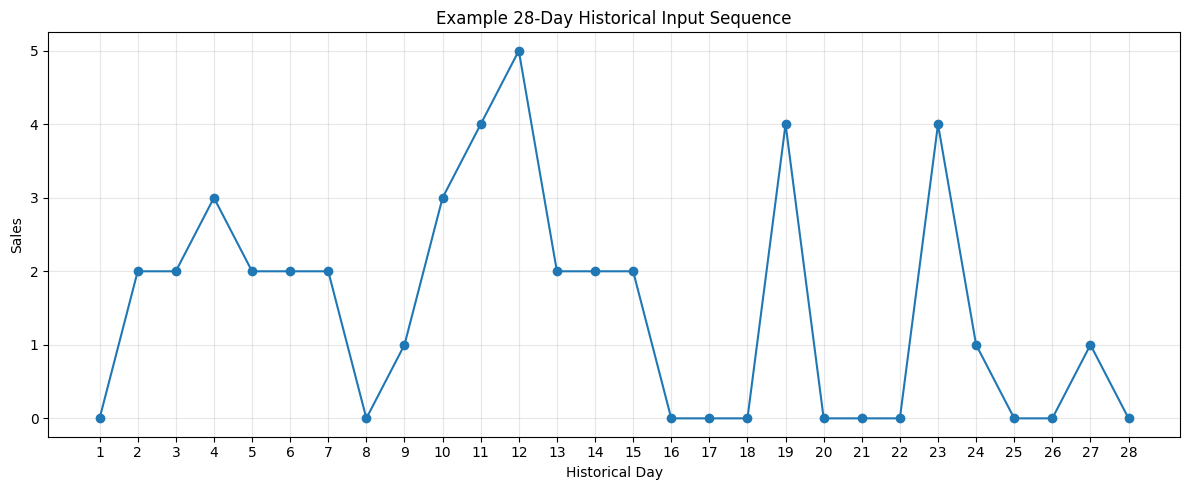

In [ ]:
SAMPLE_INDEX = 0

plt.figure(
    figsize=(12, 5)
)

plt.plot(
    np.arange(
        1,
        SEQUENCE_LENGTH + 1
    ),
    X_train_seq_raw[
        SAMPLE_INDEX
    ],
    marker="o"
)

plt.xlabel(
    "Historical Day"
)

plt.ylabel(
    "Sales"
)

plt.title(
    "Example 28-Day Historical Input Sequence"
)

plt.xticks(
    np.arange(
        1,
        29
    )
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

SEQUENCE_EXAMPLE_PATH = os.path.join(
    FIGURES_DIR,
    "lstm_example_input_sequence.png"
)

plt.savefig(
    SEQUENCE_EXAMPLE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Build LSTM model

In [ ]:
tf.keras.backend.clear_session()

lstm_model = Sequential([

    Input(
        shape=(
            SEQUENCE_LENGTH,
            1
        )
    ),

    LSTM(
        64,
        return_sequences=True
    ),

    Dropout(
        0.20
    ),

    LSTM(
        32,
        return_sequences=False
    ),

    Dropout(
        0.10
    ),

    Dense(
        64,
        activation="relu"
    ),

    Dense(
        HORIZON,
        activation="linear"
    )
])

lstm_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 28, 64)         │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 28, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 28)             │         1,820 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,244 (129.86 KB)

 Trainable params: 33,244 (129.86 KB)

 Non-trainable params: 0 (0.00 B)

Compile LSTM

In [ ]:
lstm_model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss="mae",

    metrics=[
        tf.keras.metrics.MeanAbsoluteError(
            name="mae"
        )
    ]
)

print(
    "LSTM compiled successfully."
)

LSTM compiled successfully.


Define callbacks

In [ ]:
BEST_LSTM_PATH = os.path.join(
    LSTM_MODEL_DIR,
    "best_lstm.keras"
)

lstm_early_stop = EarlyStopping(

    monitor="val_loss",

    patience=10,

    restore_best_weights=True,

    verbose=1
)

lstm_reduce_lr = ReduceLROnPlateau(

    monitor="val_loss",

    factor=0.5,

    patience=5,

    min_lr=1e-6,

    verbose=1
)

lstm_checkpoint = ModelCheckpoint(

    filepath=BEST_LSTM_PATH,

    monitor="val_loss",

    save_best_only=True,

    verbose=1
)

print(
    "LSTM callbacks ready."
)

LSTM callbacks ready.


Train LSTM

In [ ]:
history_lstm = lstm_model.fit(

    X_train_lstm,
    y_train_seq,

    validation_data=(
        X_val_lstm,
        y_val_seq
    ),

    epochs=100,

    batch_size=256,

    shuffle=True,

    callbacks=[
        lstm_early_stop,
        lstm_reduce_lr,
        lstm_checkpoint
    ],

    verbose=1
)

Epoch 1/100
309/310 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step - loss: 0.7515 - mae: 0.7515
Epoch 1: val_loss improved from None to 0.84753, saving model to /content/drive/MyDrive/GC210_Retail_Forecasting/models/lstm/best_lstm.keras

Epoch 1: finished saving model to /content/drive/MyDrive/GC210_Retail_Forecasting/models/lstm/best_lstm.keras
310/310 ━━━━━━━━━━━━━━━━━━━━ 42s 122ms/step - loss: 0.6939 - mae: 0.6939 - val_loss: 0.8475 - val_mae: 0.8475 - learning_rate: 0.0010
Epoch 2/100
310/310 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step - loss: 0.6526 - mae: 0.6526
Epoch 2: val_loss improved from 0.84753 to 0.83294, saving model to /content/drive/MyDrive/GC210_Retail_Forecasting/models/lstm/best_lstm.keras

Epoch 2: finished saving model to /content/drive/MyDrive/GC210_Retail_Forecasting/models/lstm/best_lstm.keras
310/310 ━━━━━━━━━━━━━━━━━━━━ 40s 128ms/step - loss: 0.6544 - mae: 0.6544 - val_loss: 0.8329 - val_mae: 0.8329 - learning_rate: 0.0010
Epoch 3/100
310/310 ━━━━━━━━━━━━━━━━━━━━ 0s 180ms/step - 

Plot LSTM training history

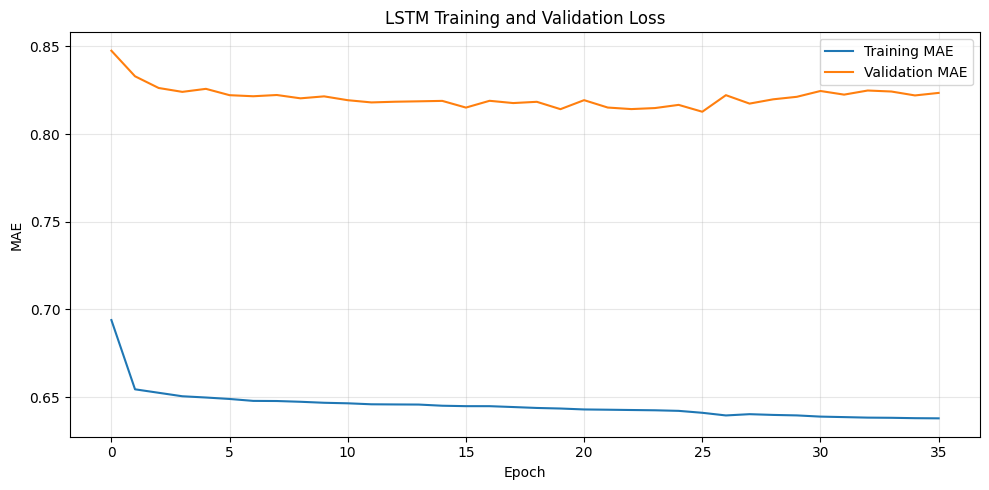

In [ ]:
plt.figure(
    figsize=(10, 5)
)

plt.plot(
    history_lstm.history["loss"],
    label="Training MAE"
)

plt.plot(
    history_lstm.history["val_loss"],
    label="Validation MAE"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "MAE"
)

plt.title(
    "LSTM Training and Validation Loss"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

LSTM_HISTORY_PATH = os.path.join(
    FIGURES_DIR,
    "lstm_training_history.png"
)

plt.savefig(
    LSTM_HISTORY_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Generate validation and test forecasts

In [ ]:
val_pred_lstm = lstm_model.predict(
    X_val_lstm,
    batch_size=256,
    verbose=0
)

test_pred_lstm = lstm_model.predict(
    X_test_lstm,
    batch_size=256,
    verbose=0
)

# Demand cannot be negative
val_pred_lstm = np.clip(
    val_pred_lstm,
    0,
    None
)

test_pred_lstm = np.clip(
    test_pred_lstm,
    0,
    None
)

print(
    "Validation prediction:",
    val_pred_lstm.shape
)

print(
    "Test prediction:",
    test_pred_lstm.shape
)

Validation prediction: (300, 28)
Test prediction: (300, 28)


Define evaluation metrics

In [ ]:
def forecast_metrics(
    y_true,
    y_pred
):

    y_true = np.asarray(
        y_true,
        dtype=np.float64
    )

    y_pred = np.asarray(
        y_pred,
        dtype=np.float64
    )

    y_pred = np.clip(
        y_pred,
        0,
        None
    )

    mae = np.mean(
        np.abs(
            y_true -
            y_pred
        )
    )

    rmse = np.sqrt(
        np.mean(
            (
                y_true -
                y_pred
            ) ** 2
        )
    )

    denominator = np.sum(
        np.abs(y_true)
    )

    if denominator > 0:

        wape = (
            np.sum(
                np.abs(
                    y_true -
                    y_pred
                )
            )
            /
            denominator
        ) * 100

    else:

        wape = np.nan

    smape_denominator = (
        np.abs(y_true)
        +
        np.abs(y_pred)
    )

    smape_values = np.divide(

        2 * np.abs(
            y_true -
            y_pred
        ),

        smape_denominator,

        out=np.zeros_like(
            y_true,
            dtype=np.float64
        ),

        where=(
            smape_denominator != 0
        )
    )

    smape = (
        np.mean(
            smape_values
        ) * 100
    )

    return {
        "MAE": float(mae),
        "RMSE": float(rmse),
        "WAPE": float(wape),
        "sMAPE": float(smape)
    }

Evaluate LSTM

In [ ]:
lstm_val_metrics = forecast_metrics(
    y_val_seq,
    val_pred_lstm
)

lstm_test_metrics = forecast_metrics(
    y_test_seq,
    test_pred_lstm
)

print("=" * 60)
print("LSTM FORECASTING RESULTS")
print("=" * 60)

print("\nVALIDATION")

for metric, value in (
    lstm_val_metrics.items()
):

    print(
        f"{metric:8s}: {value:.4f}"
    )


print("\nTEST")

for metric, value in (
    lstm_test_metrics.items()
):

    print(
        f"{metric:8s}: {value:.4f}"
    )

LSTM FORECASTING RESULTS

VALIDATION
MAE     : 0.8127
RMSE    : 1.7437
WAPE    : 68.9919
sMAPE   : 129.3016

TEST
MAE     : 0.8332
RMSE    : 1.7894
WAPE    : 70.2268
sMAPE   : 127.8854


Save final LSTM model

In [ ]:
LSTM_MODEL_PATH = os.path.join(
    LSTM_MODEL_DIR,
    "lstm_28day_forecaster.keras"
)

lstm_model.save(
    LSTM_MODEL_PATH
)

print(
    "LSTM model saved:"
)

print(
    LSTM_MODEL_PATH
)

LSTM model saved:
/content/drive/MyDrive/GC210_Retail_Forecasting/models/lstm/lstm_28day_forecaster.keras


Save LSTM metrics

In [ ]:
lstm_metrics_df = pd.DataFrame([
    {
        "Dataset":
            "Validation",

        "Model":
            "LSTM",

        **lstm_val_metrics
    },

    {
        "Dataset":
            "Test",

        "Model":
            "LSTM",

        **lstm_test_metrics
    }
])

display(
    lstm_metrics_df.round(4)
)

LSTM_METRICS_PATH = os.path.join(
    METRICS_DIR,
    "lstm_metrics.csv"
)

lstm_metrics_df.to_csv(
    LSTM_METRICS_PATH,
    index=False
)

print(
    "Saved:",
    LSTM_METRICS_PATH
)

,Dataset,Model,MAE,RMSE,WAPE,sMAPE
0,Validation,LSTM,0.8127,1.7437,68.9919,129.3016
1,Test,LSTM,0.8332,1.7894,70.2268,127.8854


Saved: /content/drive/MyDrive/GC210_Retail_Forecasting/results/metrics/lstm_metrics.csv


Save test predictions

In [ ]:
prediction_records = []

for i in range(
    len(test_meta)
):

    series_key = (
        test_meta.iloc[i][
            "series_key"
        ]
    )

    origin_date = (
        test_meta.iloc[i][
            "origin_date"
        ]
    )

    for h in range(
        HORIZON
    ):

        prediction_records.append({

            "series_id":
                series_key,

            "origin_date":
                origin_date,

            "forecast_day":
                h + 1,

            "actual":
                float(
                    y_test_seq[
                        i,
                        h
                    ]
                ),

            "prediction":
                float(
                    test_pred_lstm[
                        i,
                        h
                    ]
                ),

            "model":
                "LSTM"
        })


lstm_predictions_df = pd.DataFrame(
    prediction_records
)

display(
    lstm_predictions_df.head()
)

,series_id,origin_date,forecast_day,actual,prediction,model
0,FOODS_1_005_TX_3,2016-04-24,1,1.0,0.957404,LSTM
1,FOODS_1_005_TX_3,2016-04-24,2,0.0,0.973581,LSTM
2,FOODS_1_005_TX_3,2016-04-24,3,4.0,0.971469,LSTM
3,FOODS_1_005_TX_3,2016-04-24,4,1.0,1.018721,LSTM
4,FOODS_1_005_TX_3,2016-04-24,5,1.0,1.005409,LSTM


In [ ]:
LSTM_PREDICTIONS_PATH = os.path.join(
    PREDICTIONS_DIR,
    "lstm_test_predictions.csv"
)

lstm_predictions_df.to_csv(
    LSTM_PREDICTIONS_PATH,
    index=False
)

print(
    "Saved:",
    LSTM_PREDICTIONS_PATH
)

Saved: /content/drive/MyDrive/GC210_Retail_Forecasting/results/predictions/lstm_test_predictions.csv


Calculate error across 28 forecast days

In [ ]:
lstm_horizon_mae = np.mean(
    np.abs(
        y_test_seq -
        test_pred_lstm
    ),
    axis=0
)

lstm_horizon_rmse = np.sqrt(
    np.mean(
        (
            y_test_seq -
            test_pred_lstm
        ) ** 2,
        axis=0
    )
)

lstm_horizon_df = pd.DataFrame({

    "Forecast_Day":
        np.arange(
            1,
            HORIZON + 1
        ),

    "LSTM_MAE":
        lstm_horizon_mae,

    "LSTM_RMSE":
        lstm_horizon_rmse
})

display(
    lstm_horizon_df.round(4)
)

,Forecast_Day,LSTM_MAE,LSTM_RMSE
0,1,0.7126,1.4891
1,2,0.7562,1.4211
2,3,0.7504,1.6020
3,4,0.7957,1.9657
4,5,0.7684,1.3768
5,6,0.8400,2.4394
6,7,0.9814,2.1164
7,8,0.7680,1.6161
8,9,0.8043,1.6531
9,10,0.6585,1.2464


In [ ]:
LSTM_HORIZON_PATH = os.path.join(
    METRICS_DIR,
    "lstm_horizon_metrics.csv"
)

lstm_horizon_df.to_csv(
    LSTM_HORIZON_PATH,
    index=False
)

Plot LSTM error across forecast horizon

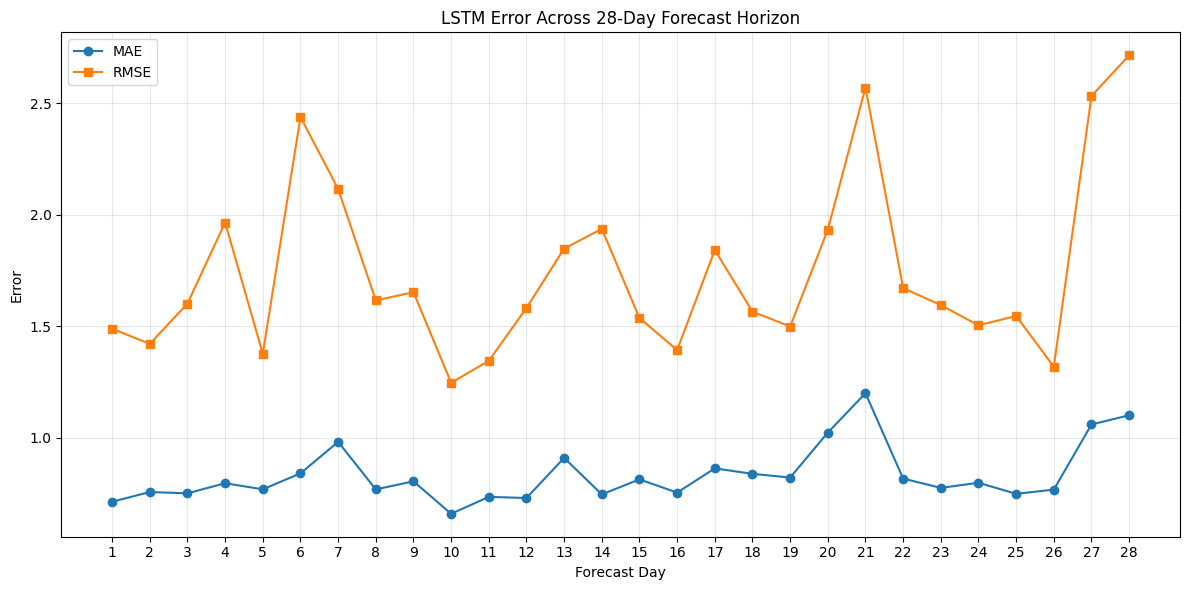

In [ ]:
plt.figure(
    figsize=(12, 6)
)

plt.plot(
    lstm_horizon_df[
        "Forecast_Day"
    ],
    lstm_horizon_df[
        "LSTM_MAE"
    ],
    marker="o",
    label="MAE"
)

plt.plot(
    lstm_horizon_df[
        "Forecast_Day"
    ],
    lstm_horizon_df[
        "LSTM_RMSE"
    ],
    marker="s",
    label="RMSE"
)

plt.xlabel(
    "Forecast Day"
)

plt.ylabel(
    "Error"
)

plt.title(
    "LSTM Error Across 28-Day Forecast Horizon"
)

plt.xticks(
    np.arange(
        1,
        29
    )
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

LSTM_HORIZON_FIGURE = os.path.join(
    FIGURES_DIR,
    "lstm_horizon_error.png"
)

plt.savefig(
    LSTM_HORIZON_FIGURE,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Plot actual vs predicted for one series

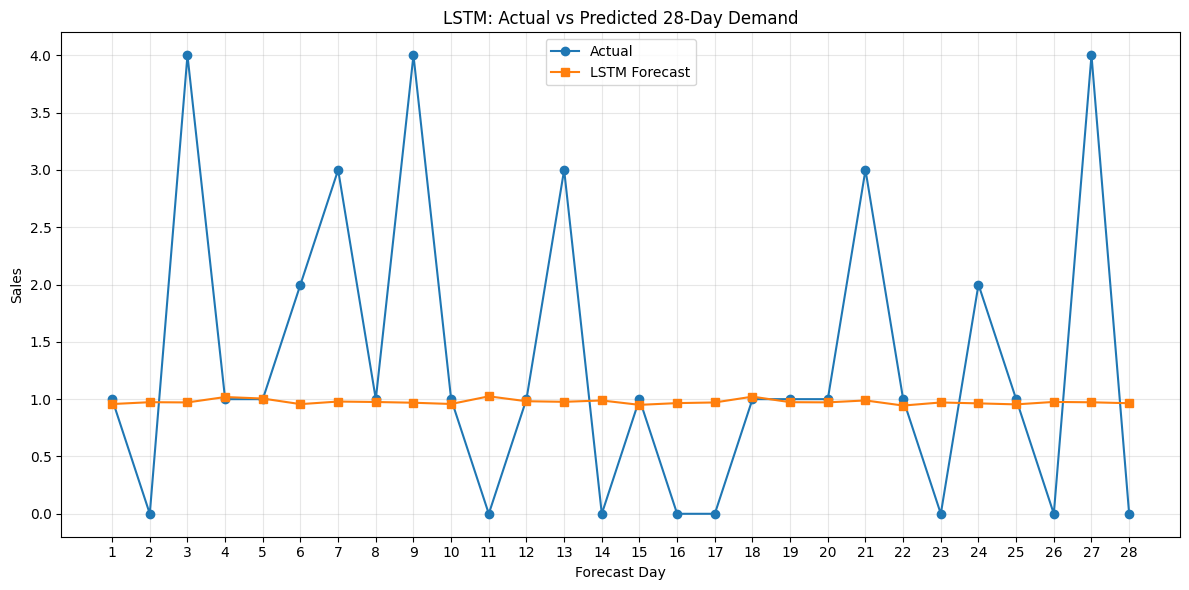

In [ ]:
SAMPLE_INDEX = 0

days = np.arange(
    1,
    HORIZON + 1
)

plt.figure(
    figsize=(12, 6)
)

plt.plot(
    days,
    y_test_seq[
        SAMPLE_INDEX
    ],
    marker="o",
    label="Actual"
)

plt.plot(
    days,
    test_pred_lstm[
        SAMPLE_INDEX
    ],
    marker="s",
    label="LSTM Forecast"
)

plt.xlabel(
    "Forecast Day"
)

plt.ylabel(
    "Sales"
)

plt.title(
    "LSTM: Actual vs Predicted 28-Day Demand"
)

plt.xticks(
    days
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

LSTM_FORECAST_FIGURE = os.path.join(
    FIGURES_DIR,
    "lstm_actual_vs_predicted.png"
)

plt.savefig(
    LSTM_FORECAST_FIGURE,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Compare LSTM with previous models

In [ ]:
REPRESENTATION_PATH = os.path.join(
    METRICS_DIR,
    "representation_learning_model_comparison.csv"
)

if os.path.exists(
    REPRESENTATION_PATH
):

    model_comparison = pd.read_csv(
        REPRESENTATION_PATH
    )

else:

    BASELINE_PATH = os.path.join(
        METRICS_DIR,
        "baseline_test_metrics.csv"
    )

    model_comparison = pd.read_csv(
        BASELINE_PATH
    )

display(
    model_comparison
)

,Model,MAE,RMSE,WAPE,sMAPE
0,Seasonal Naive,1.255476,2.874394,105.819787,86.528972
1,MLP,0.900348,1.843470,75.887268,151.595465
2,LightGBM,0.846885,1.805397,71.381020,102.498205
3,AE + MLP,1.066171,1.808892,89.863924,136.164417
4,DAE + MLP,1.190485,2.897811,100.341905,128.139835
5,SAE + MLP,0.924803,1.948042,77.948489,125.472352


In [ ]:
lstm_result = pd.DataFrame([{

    "Model":
        "LSTM",

    "MAE":
        lstm_test_metrics[
            "MAE"
        ],

    "RMSE":
        lstm_test_metrics[
            "RMSE"
        ],

    "WAPE":
        lstm_test_metrics[
            "WAPE"
        ],

    "sMAPE":
        lstm_test_metrics[
            "sMAPE"
        ]
}])

In [ ]:
model_comparison = (
    model_comparison[
        model_comparison[
            "Model"
        ] != "LSTM"
    ]
    .copy()
)

step10_model_comparison = pd.concat(
    [
        model_comparison,
        lstm_result
    ],
    ignore_index=True
)

display(
    step10_model_comparison.round(4)
)

,Model,MAE,RMSE,WAPE,sMAPE
0,Seasonal Naive,1.2555,2.8744,105.8198,86.5290
1,MLP,0.9003,1.8435,75.8873,151.5955
2,LightGBM,0.8469,1.8054,71.3810,102.4982
3,AE + MLP,1.0662,1.8089,89.8639,136.1644
4,DAE + MLP,1.1905,2.8978,100.3419,128.1398
5,SAE + MLP,0.9248,1.9480,77.9485,125.4724
6,LSTM,0.8332,1.7894,70.2268,127.8854


Save updated comparison

In [ ]:
STEP10_COMPARISON_PATH = os.path.join(
    METRICS_DIR,
    "models_with_lstm_comparison.csv"
)

step10_model_comparison.to_csv(
    STEP10_COMPARISON_PATH,
    index=False
)

print(
    "Saved:",
    STEP10_COMPARISON_PATH
)

Saved: /content/drive/MyDrive/GC210_Retail_Forecasting/results/metrics/models_with_lstm_comparison.csv


Save sequence configuration

In [ ]:
sequence_config = {

    "sequence_length":
        SEQUENCE_LENGTH,

    "sequence_feature":
        "historical_sales",

    "input_shape": [
        SEQUENCE_LENGTH,
        1
    ],

    "forecast_horizon":
        HORIZON,

    "model":
        "LSTM",

    "architecture": [
        "LSTM(64, return_sequences=True)",
        "Dropout(0.20)",
        "LSTM(32)",
        "Dropout(0.10)",
        "Dense(64, relu)",
        "Dense(28, linear)"
    ],

    "loss":
        "MAE",

    "optimizer":
        "Adam",

    "learning_rate":
        0.001
}

SEQUENCE_CONFIG_PATH = os.path.join(
    LSTM_MODEL_DIR,
    "lstm_config.json"
)

with open(
    SEQUENCE_CONFIG_PATH,
    "w"
) as f:

    json.dump(
        sequence_config,
        f,
        indent=4
    )

print(
    "Configuration saved:",
    SEQUENCE_CONFIG_PATH
)

Configuration saved: /content/drive/MyDrive/GC210_Retail_Forecasting/models/lstm/lstm_config.json


Final verification

In [ ]:
print("=" * 80)
print("STEP 10 - TEMPORAL SEQUENCE + LSTM FINAL VERIFICATION")
print("=" * 80)

print("\n1. TEMPORAL INPUT")
print("-" * 45)

print(
    "Sequence length:",
    SEQUENCE_LENGTH
)

print(
    "Features per timestep:",
    X_train_lstm.shape[2]
)

print(
    "Forecast horizon:",
    HORIZON
)


print("\n2. SEQUENCE SHAPES")
print("-" * 45)

print(
    "Train:",
    X_train_lstm.shape,
    "->",
    y_train_seq.shape
)

print(
    "Validation:",
    X_val_lstm.shape,
    "->",
    y_val_seq.shape
)

print(
    "Test:",
    X_test_lstm.shape,
    "->",
    y_test_seq.shape
)


print("\n3. DATA QUALITY")
print("-" * 45)

print(
    "Train finite:",
    np.isfinite(
        X_train_lstm
    ).all()
)

print(
    "Validation finite:",
    np.isfinite(
        X_val_lstm
    ).all()
)

print(
    "Test finite:",
    np.isfinite(
        X_test_lstm
    ).all()
)


print("\n4. LSTM TEST METRICS")
print("-" * 45)

for metric, value in (
    lstm_test_metrics.items()
):

    print(
        f"{metric:8s}: "
        f"{value:.4f}"
    )


print("\n5. SAVED FILES")
print("-" * 45)

files_to_check = {

    "Train sequences":
        TRAIN_SEQUENCE_PATH,

    "Validation sequences":
        VAL_SEQUENCE_PATH,

    "Test sequences":
        TEST_SEQUENCE_PATH,

    "Sequence scaler":
        SEQUENCE_SCALER_PATH,

    "LSTM model":
        LSTM_MODEL_PATH,

    "LSTM metrics":
        LSTM_METRICS_PATH,

    "LSTM predictions":
        LSTM_PREDICTIONS_PATH,

    "LSTM horizon metrics":
        LSTM_HORIZON_PATH,

    "LSTM configuration":
        SEQUENCE_CONFIG_PATH,

    "Model comparison":
        STEP10_COMPARISON_PATH
}

all_saved = True

for name, path in (
    files_to_check.items()
):

    exists = os.path.exists(
        path
    )

    print(
        f"{name:28s}:",
        "FOUND"
        if exists
        else "MISSING"
    )

    if not exists:
        all_saved = False


print("\n" + "=" * 80)

if all_saved:

    print(
        "STEP 10 COMPLETED SUCCESSFULLY"
    )

    print(
        "28-DAY HISTORY -> LSTM -> "
        "28-DAY DEMAND FORECAST"
    )

else:

    print(
        "STEP 10 INCOMPLETE - "
        "CHECK MISSING FILES ABOVE"
    )

print("=" * 80)

STEP 10 - TEMPORAL SEQUENCE + LSTM FINAL VERIFICATION

1. TEMPORAL INPUT
---------------------------------------------
Sequence length: 28
Features per timestep: 1
Forecast horizon: 28

2. SEQUENCE SHAPES
---------------------------------------------
Train: (79200, 28, 1) -> (79200, 28)
Validation: (300, 28, 1) -> (300, 28)
Test: (300, 28, 1) -> (300, 28)

3. DATA QUALITY
---------------------------------------------
Train finite: True
Validation finite: True
Test finite: True

4. LSTM TEST METRICS
---------------------------------------------
MAE     : 0.8332
RMSE    : 1.7894
WAPE    : 70.2268
sMAPE   : 127.8854

5. SAVED FILES
---------------------------------------------
Train sequences             : FOUND
Validation sequences        : FOUND
Test sequences              : FOUND
Sequence scaler             : FOUND
LSTM model                  : FOUND
LSTM metrics                : FOUND
LSTM predictions            : FOUND
LSTM horizon metrics        : FOUND
LSTM configuration          :